In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:41551")
client

<Client: 'tcp://127.0.0.1:41551' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import geostrokit as qg

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
ds = xr.open_dataset(op.join(ddir,"MSQG/vars_0009.nc")
                    ).isel(time=slice(50,None)
                          ).chunk({"time":4,"level":1,"y":128,"x":256})
dsin = xr.open_dataset(op.join(ddir,"MSQG/input_vars_5l_N1024.nc")
                      ).isel(t=0).chunk({"z":1,"y":128,"x":256})
ds, dsin

(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
 Attributes:
     history:  Mon Sep 14 12:31:23 2026: ncrcat -O tmp_vars/vars_0015.nc tmp_v...
     NCO:      netCDF Operators version 5.1.9 (Homepage = http://nco.sf.net, C...,
 <xarray.Dataset> Size: 27MB
 Dimensions:  (z: 5, y: 513, x: 1025)
 Coordinates:
   * z        (z) float32 20B 0.0 1.0 2.0 3.

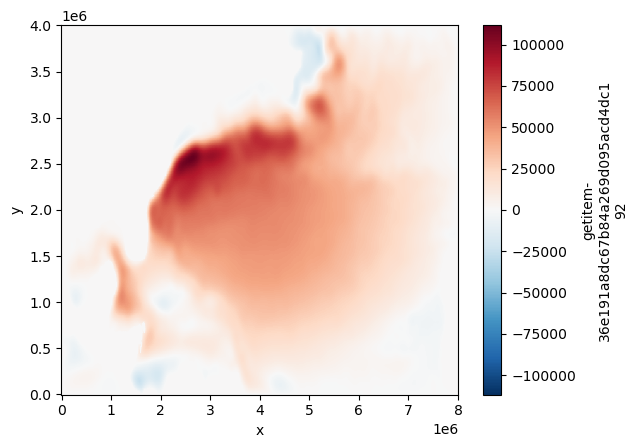

In [5]:
sshb = xr.DataArray(dsin.psi_pg.isel(z=0).data,
                   dims=["y","x"],
                   coords={"y":ds.y.data,"x":ds.x.data}
                  )
sshb.plot(rasterized=True)

In [6]:
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":ds.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(Z,Zp1)

ds["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                         coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                        )
ds["Z"] = xr.DataArray(Z, dims="level",
                       coords={"level":ds.level.data}
                      )

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds, grid

[ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025, lp1: 6, yG: 512, xG: 1024)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 2kB 3.906e+03 1.172e+04 ... 3.988e+06 3.996e+06
   * xG       (xG) float32 4kB 3.906e+03 1.172e+04 ... 7.988e+06 7.996e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+0

In [7]:
Delta = 3.90625e+03
u = -(grid.diff(ds.psi.fillna(0.).chunk({"y":-1}),"Y",padding="extend") 
      / Delta)
v = (grid.diff(ds.psi.fillna(0.).chunk({"x":-1}),"X",padding="extend") 
     / Delta)
uq = (grid.interp(u,"Y",padding="extend")
      * ds.q).mean("time")
vq = (grid.interp(v,"X",padding="extend")
      * ds.q).mean("time")

# il = 0
# u, v = qg.comp_vel(ds.psi.isel(level=il).values, Delta, 'dirichlet_face')
# u = xr.DataArray(u, dims=ds.psi.isel(level=il).dims, 
#                   coords=ds.psi.isel(level=il).coords
#                  ).chunk(ds.psi.isel(level=il).chunks)
# v = xr.DataArray(v, dims=ds.psi.isel(level=il).dims, 
#                   coords=ds.psi.isel(level=il).coords
#                  ).chunk(ds.psi.isel(level=il).chunks)
# print(u, v)
# uq = (u * ds.q.isel(level=il)).mean("time").compute()
# vq = (v * ds.q.isel(level=il)).mean("time").compute()

uq, vq

(<xarray.DataArray (level: 5, y: 513, x: 1025)> Size: 11MB
 dask.array<mean_agg-aggregate, shape=(5, 513, 1025), dtype=float32, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06,
 <xarray.DataArray (level: 5, y: 513, x: 1025)> Size: 11MB
 dask.array<mean_agg-aggregate, shape=(5, 513, 1025), dtype=float32, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06)

In [8]:
dsin = xr.open_dataset(op.join(ddir,"MSQG/input_vars_5l_N1024.nc")
                      ).isel(t=0).chunk({"z":1,"y":128,"x":256})
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]

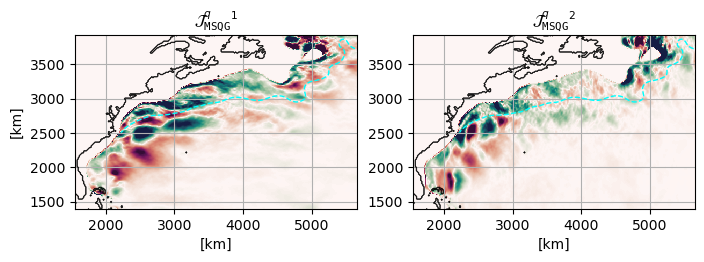

In [40]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

ax1.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               uq.isel(level=1), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.7e-5, vmax=1.7e-5,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               vq.isel(level=1), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.7e-5, vmax=1.7e-5,
               zorder=0,
               # rasterized=True
              )

ax1.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_MSQG.pdf"), dpi=200)

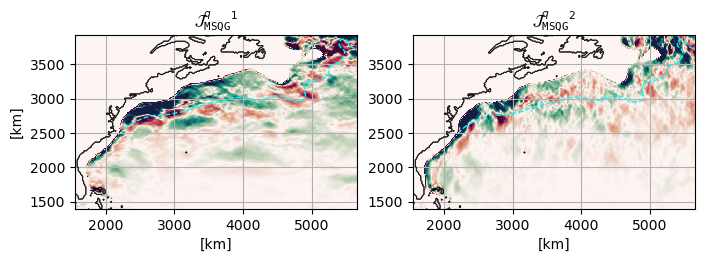

In [11]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

ax1.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               uq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.2e-5, vmax=1.2e-5,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               vq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.2e-5, vmax=1.2e-5,
               zorder=0,
               # rasterized=True
              )

ax1.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_MSQGsurf.pdf"), dpi=200)

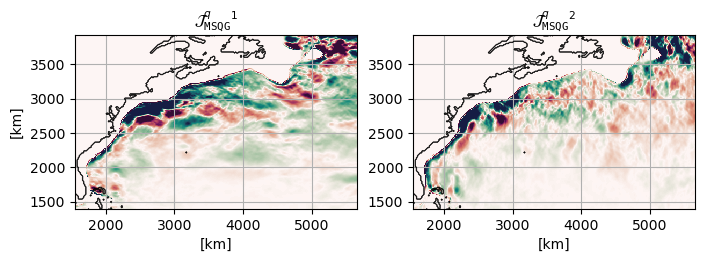

In [16]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig, axes = plt.subplots(figsize=(8,4), nrows=1, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0]
ax2 = axes[1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )

ax1.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               uq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.e-5, vmax=1.e-5,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               vq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.e-5, vmax=1.e-5,
               zorder=0,
               # rasterized=True
              )

ax1.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_xlabel(r"[km]")
ax2.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")

ax1.grid(True)
ax2.grid(True)

ax1.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{q}_{\tt MSQG}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_MSQGsurf_geostrokit.pdf"), dpi=200)

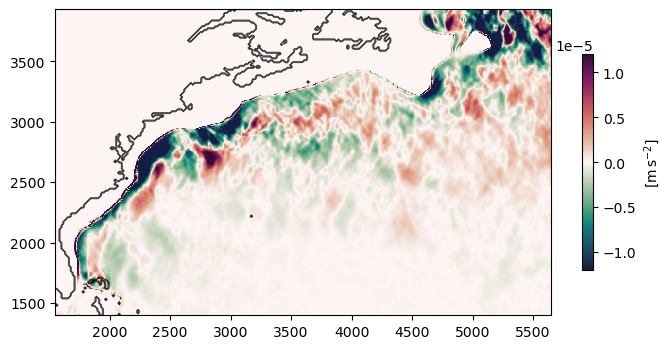

In [12]:
xmax = 5650
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(8,4))
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
                vq.isel(level=0), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.2e-5, vmax=1.2e-5,
               rasterized=True)

ax6.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6, shrink=.7)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/PVflux_MSQG_cbar.pdf"))

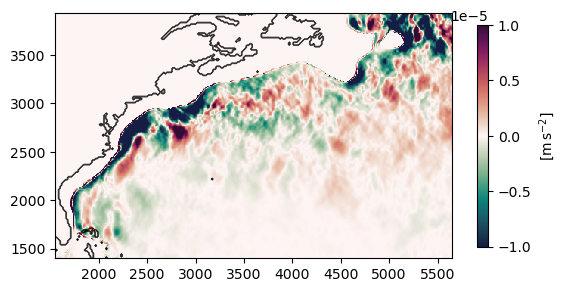

In [17]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
                vq, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-1.7e-5, vmax=1.7e-5,
               rasterized=True)

ax6.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6, shrink=.6)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/PVflux_MSQGgeostrokit_cbar.pdf"))